In [ ]:
!pip -q install scikit-learn seaborn

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    accuracy_score, precision_recall_fscore_support,
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve
)

np.random.seed(42)


In [ ]:
n = 292

D = np.random.uniform(4, 400, n)
VL = np.random.uniform(0, 1, n)
VR = np.random.uniform(0, 1, n)

# Auxiliary IR distances used for rule-based label generation
D_left = np.random.uniform(5, 200, n)
D_right = np.random.uniform(5, 200, n)

# 0 = No Turn, 1 = Left Turn, 2 = Right Turn
y = np.where(
    D > 120,
    0,
    np.where(D_left > D_right, 1, 2)
)

data = pd.DataFrame({
    "D": D,
    "VL": VL,
    "VR": VR,
    "D_left": D_left,
    "D_right": D_right,
    "Label": y
})

print(data.head())
print("Shape:", data.shape)


            D        VL        VR      D_left     D_right  Label
0  152.317887  0.822601  0.633401  144.614585    6.245245      0
1  380.482865  0.360191  0.240146  133.490169   60.972436      0
2  293.869601  0.127061  0.075863   10.283719  125.300749      0
3  241.068760  0.522243  0.128880   48.284572  196.331305      0
4   65.783382  0.769994  0.128046   50.059585  128.203638      2
Shape: (292, 6)


Label
0    202
1     48
2     42
Name: count, dtype: int64


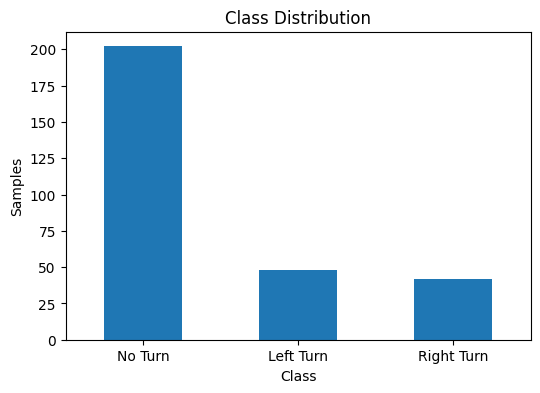

In [ ]:
print(data["Label"].value_counts().sort_index())

plt.figure(figsize=(6,4))
data["Label"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("Class")
plt.ylabel("Samples")
plt.title("Class Distribution")
plt.xticks([0,1,2], ["No Turn", "Left Turn", "Right Turn"], rotation=0)
plt.show()


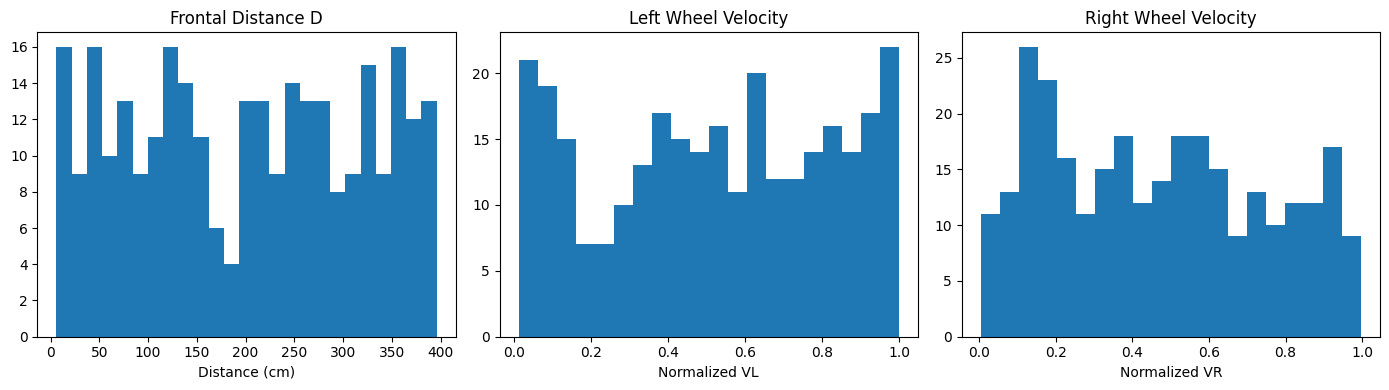

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14,4))

axes[0].hist(data["D"], bins=25)
axes[0].set_title("Frontal Distance D")
axes[0].set_xlabel("Distance (cm)")

axes[1].hist(data["VL"], bins=20)
axes[1].set_title("Left Wheel Velocity")
axes[1].set_xlabel("Normalized VL")

axes[2].hist(data["VR"], bins=20)
axes[2].set_title("Right Wheel Velocity")
axes[2].set_xlabel("Normalized VR")

plt.tight_layout()
plt.show()


In [ ]:
# Main classifier inputs described in the paper
X = data[["D", "VL", "VR"]].values
y = data["Label"].values

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (292, 3)
y shape: (292,)


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples :", len(X_test))


Training samples: 233
Testing samples : 59


In [ ]:
scaler = StandardScaler()

X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# Add bias term
X_train_b = np.c_[X_train_s, np.ones(len(X_train_s))]
X_test_b = np.c_[X_test_s, np.ones(len(X_test_s))]

print("Training matrix:", X_train_b.shape)
print("Testing matrix :", X_test_b.shape)


Training matrix: (233, 4)
Testing matrix : (59, 4)


In [ ]:
def softmax(z):
    z = z - np.max(z, axis=1, keepdims=True)
    exp_z = np.exp(z)
    return exp_z / np.sum(exp_z, axis=1, keepdims=True)


In [ ]:
def loss_fn(W, X, y, lam=1e-2):
    P = softmax(X @ W)
    n = len(y)

    nll = -np.mean(
        np.log(P[np.arange(n), y] + 1e-12)
    )

    # L2 regularization; bias is not penalized
    reg = 0.5 * lam * np.sum(W[:-1] ** 2)

    return nll + reg


In [ ]:
def gradient_fn(W, X, y, lam=1e-2):
    P = softmax(X @ W)

    Y = np.zeros_like(P)
    Y[np.arange(len(y)), y] = 1

    grad = (X.T @ (P - Y)) / len(y)

    # L2 regularization except bias
    grad[:-1] += lam * W[:-1]

    return grad


In [ ]:

def train_abcd_lor(
    X, y,
    n_classes=3,
    lam=1e-2,
    iterations=100,
    step_size=0.15
):
    W = np.zeros((X.shape[1], n_classes))

    # B1 = D + Bias
    # B2 = VL + VR
    blocks = [
        [0, 3],
        [1, 2]
    ]

    history = []
    selected_blocks = []

    for t in range(iterations):

        grad = gradient_fn(W, X, y, lam)

        candidate_losses = []

        for block in blocks:
            W_candidate = W.copy()

            W_candidate[block] -= step_size * grad[block]

            candidate_loss = loss_fn(
                W_candidate, X, y, lam
            )
            candidate_losses.append(candidate_loss)

        # Select block with lowest candidate loss
        best_idx = int(np.argmin(candidate_losses))
        best_block = blocks[best_idx]

        # Update selected block
        W[best_block] -= step_size * grad[best_block]

        # Store current loss
        current_loss = loss_fn(W, X, y, lam)
        history.append(current_loss)

        selected_blocks.append(best_idx)

    return W, history, selected_blocks


In [ ]:
W_abcd, history_abcd, selected_blocks = train_abcd_lor(
    X_train_b,
    y_train,
    lam=1e-2,
    iterations=100,
    step_size=0.15
)

print("Training completed.")
print("Final loss:", history_abcd[-1])
print("Weight matrix shape:", W_abcd.shape)


Training completed.
Final loss: 0.43519665365035276
Weight matrix shape: (4, 3)


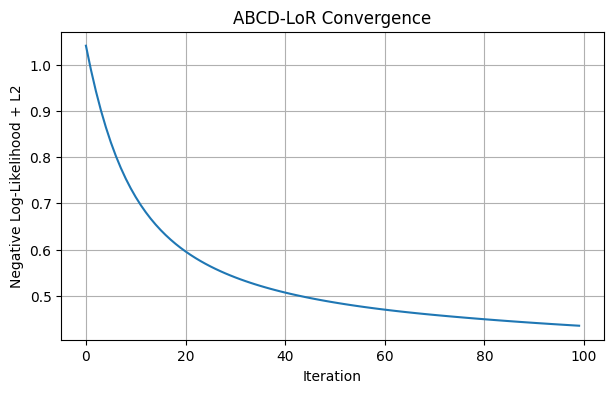

In [ ]:
plt.figure(figsize=(7,4))
plt.plot(history_abcd)
plt.xlabel("Iteration")
plt.ylabel("Negative Log-Likelihood + L2")
plt.title("ABCD-LoR Convergence")
plt.grid(True)
plt.show()


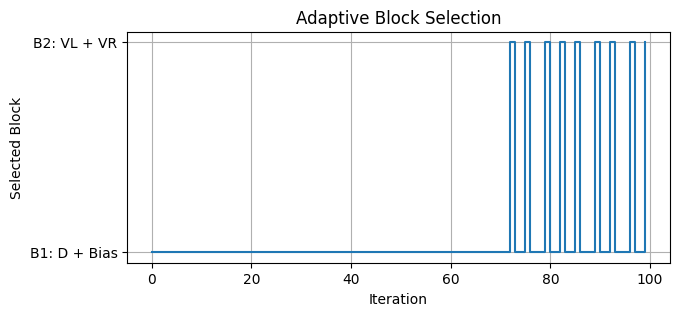

In [ ]:
plt.figure(figsize=(7,3))
plt.step(
    range(len(selected_blocks)),
    selected_blocks,
    where="post"
)
plt.xlabel("Iteration")
plt.ylabel("Selected Block")
plt.yticks([0,1], ["B1: D + Bias", "B2: VL + VR"])
plt.title("Adaptive Block Selection")
plt.grid(True)
plt.show()


In [ ]:
def predict_abcd(X, W):
    P = softmax(X @ W)
    pred = np.argmax(P, axis=1)
    return pred, P

y_pred_abcd, y_prob_abcd = predict_abcd(
    X_test_b,
    W_abcd
)

print("ABCD-LoR Accuracy:",
      accuracy_score(y_test, y_pred_abcd))


ABCD-LoR Accuracy: 0.8305084745762712


In [ ]:
print(
    classification_report(
        y_test,
        y_pred_abcd,
        target_names=[
            "No Turn",
            "Left Turn",
            "Right Turn"
        ],
        zero_division=0
    )
)


              precision    recall  f1-score   support

     No Turn       0.98      1.00      0.99        41
   Left Turn       0.50      0.80      0.62        10
  Right Turn       0.00      0.00      0.00         8

    accuracy                           0.83        59
   macro avg       0.49      0.60      0.53        59
weighted avg       0.76      0.83      0.79        59



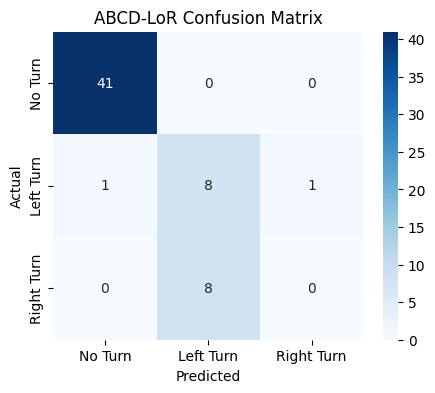

In [ ]:
cm = confusion_matrix(
    y_test,
    y_pred_abcd
)

plt.figure(figsize=(5,4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "No Turn",
        "Left Turn",
        "Right Turn"
    ],
    yticklabels=[
        "No Turn",
        "Left Turn",
        "Right Turn"
    ]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("ABCD-LoR Confusion Matrix")
plt.show()


In [ ]:
probability_table = pd.DataFrame(
    y_prob_abcd,
    columns=[
        "P(No Turn)",
        "P(Left Turn)",
        "P(Right Turn)"
    ]
)

print(probability_table.head(10))


   P(No Turn)  P(Left Turn)  P(Right Turn)
0    0.910048      0.048249       0.041704
1    0.914889      0.046441       0.038670
2    0.487856      0.298687       0.213456
3    0.982769      0.009583       0.007649
4    0.985624      0.007958       0.006418
5    0.993552      0.003115       0.003333
6    0.116532      0.508497       0.374971
7    0.975050      0.011702       0.013248
8    0.214528      0.413650       0.371822
9    0.779658      0.115599       0.104744


In [ ]:
lr = LogisticRegression(
    multi_class="multinomial",
    max_iter=2000,
    C=100
)

lr.fit(X_train_s, y_train)

pred_lr = lr.predict(X_test_s)

print(
    "Standard Logistic Regression Accuracy:",
    accuracy_score(y_test, pred_lr)
)


Standard Logistic Regression Accuracy: 0.847457627118644


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


In [ ]:
knn = KNeighborsClassifier(
    n_neighbors=5
)

knn.fit(X_train_s, y_train)

pred_knn = knn.predict(X_test_s)

print(
    "KNN Accuracy:",
    accuracy_score(y_test, pred_knn)
)


KNN Accuracy: 0.8135593220338984


In [ ]:
gb = GradientBoostingClassifier(
    random_state=42
)

gb.fit(X_train_s, y_train)

pred_gb = gb.predict(X_test_s)

print(
    "Gradient Boosting Accuracy:",
    accuracy_score(y_test, pred_gb)
)


Gradient Boosting Accuracy: 0.7796610169491526


In [ ]:
X_train_bin = (X_train_s > 0).astype(int)
X_test_bin = (X_test_s > 0).astype(int)

bnb = BernoulliNB()

bnb.fit(X_train_bin, y_train)

pred_bnb = bnb.predict(X_test_bin)

print(
    "Bernoulli Naive Bayes Accuracy:",
    accuracy_score(y_test, pred_bnb)
)


Bernoulli Naive Bayes Accuracy: 0.711864406779661


In [ ]:
results = pd.DataFrame({
    "Model": [
        "ABCD-LoR",
        "Standard Logistic Regression",
        "KNN",
        "Gradient Boosting",
        "Bernoulli Naive Bayes"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_abcd),
        accuracy_score(y_test, pred_lr),
        accuracy_score(y_test, pred_knn),
        accuracy_score(y_test, pred_gb),
        accuracy_score(y_test, pred_bnb)
    ]
})

print(results)


                          Model  Accuracy
0                      ABCD-LoR  0.830508
1  Standard Logistic Regression  0.847458
2                           KNN  0.813559
3             Gradient Boosting  0.779661
4         Bernoulli Naive Bayes  0.711864


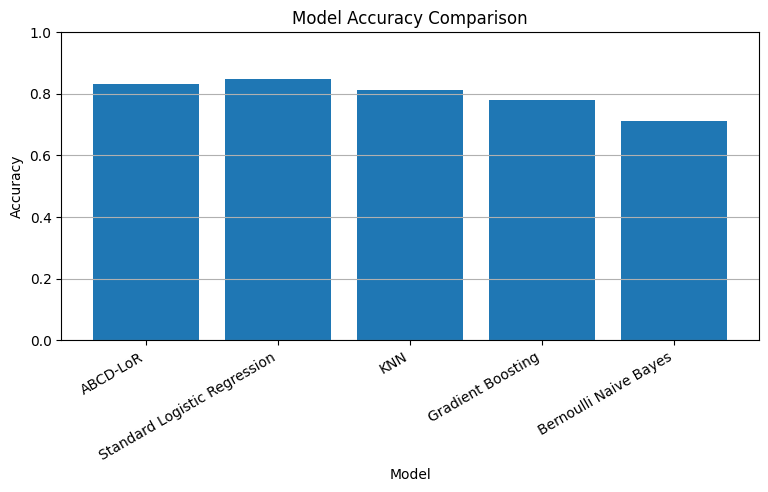

In [ ]:
plt.figure(figsize=(9,4))

plt.bar(
    results["Model"],
    results["Accuracy"]
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Model Accuracy Comparison")
plt.xticks(rotation=30, ha="right")
plt.ylim(0,1)
plt.grid(axis="y")

plt.show()


In [ ]:
lr_prob = lr.predict_proba(X_test_s)
knn_prob = knn.predict_proba(X_test_s)
gb_prob = gb.predict_proba(X_test_s)
bnb_prob = bnb.predict_proba(X_test_bin)

y_test_bin = label_binarize(
    y_test,
    classes=[0,1,2]
)

abcd_auc = roc_auc_score(
    y_test_bin,
    y_prob_abcd,
    multi_class="ovr",
    average="macro"
)

lr_auc = roc_auc_score(
    y_test_bin,
    lr_prob,
    multi_class="ovr",
    average="macro"
)

gb_auc = roc_auc_score(
    y_test_bin,
    gb_prob,
    multi_class="ovr",
    average="macro"
)

print("ABCD-LoR Macro ROC-AUC:", abcd_auc)
print("Logistic Regression Macro ROC-AUC:", lr_auc)
print("Gradient Boosting Macro ROC-AUC:", gb_auc)


ABCD-LoR Macro ROC-AUC: 0.9387588368680806
Logistic Regression Macro ROC-AUC: 0.9312625050020008
Gradient Boosting Macro ROC-AUC: 0.914655862344938


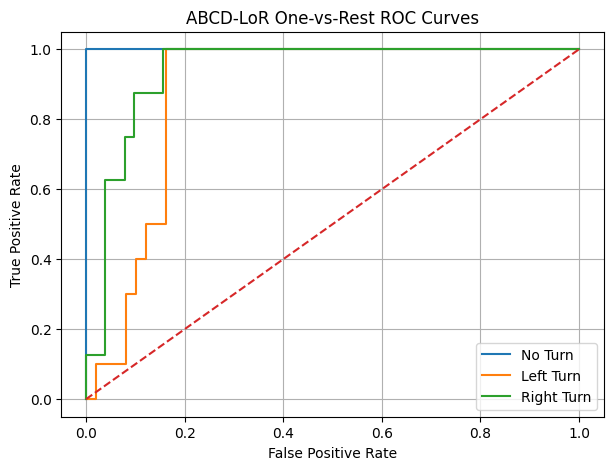

In [ ]:
plt.figure(figsize=(7,5))

for class_id, class_name in enumerate(
    ["No Turn", "Left Turn", "Right Turn"]
):
    fpr, tpr, _ = roc_curve(
        y_test_bin[:, class_id],
        y_prob_abcd[:, class_id]
    )

    plt.plot(
        fpr,
        tpr,
        label=class_name
    )

plt.plot([0,1], [0,1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ABCD-LoR One-vs-Rest ROC Curves")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_scores = []

for fold, (tr_idx, va_idx) in enumerate(
    skf.split(X, y),
    start=1
):

    Xtr = scaler.fit_transform(X[tr_idx])
    Xva = scaler.transform(X[va_idx])

    Xtr_b = np.c_[
        Xtr,
        np.ones(len(Xtr))
    ]

    Xva_b = np.c_[
        Xva,
        np.ones(len(Xva))
    ]

    W, _, _ = train_abcd_lor(
        Xtr_b,
        y[tr_idx],
        lam=1e-2,
        iterations=100,
        step_size=0.15
    )

    pred, _ = predict_abcd(
        Xva_b,
        W
    )

    score = accuracy_score(
        y[va_idx],
        pred
    )

    cv_scores.append(score)

    print(
        f"Fold {fold}: {score:.4f}"
    )

print("Mean CV Accuracy:", np.mean(cv_scores))
print("Std CV Accuracy :", np.std(cv_scores))


Fold 1: 0.8305
Fold 2: 0.7966
Fold 3: 0.7931
Fold 4: 0.8448
Fold 5: 0.7759
Mean CV Accuracy: 0.8081823495032145
Std CV Accuracy : 0.025484184822470963


In [ ]:
def train_fixed_bcd(
    X, y,
    n_classes=3,
    lam=1e-2,
    iterations=100,
    step_size=0.15
):
    W = np.zeros(
        (X.shape[1], n_classes)
    )

    blocks = [
        [0,3],
        [1,2]
    ]

    history = []

    for t in range(iterations):

        grad = gradient_fn(
            W, X, y, lam
        )

        # Fixed alternating update
        block = blocks[t % 2]

        W[block] -= (
            step_size * grad[block]
        )

        history.append(
            loss_fn(W, X, y, lam)
        )

    return W, history

W_fixed, history_fixed = train_fixed_bcd(
    X_train_b,
    y_train
)

pred_fixed, _ = predict_abcd(
    X_test_b,
    W_fixed
)

print(
    "Fixed BCD Accuracy:",
    accuracy_score(y_test, pred_fixed)
)


Fixed BCD Accuracy: 0.847457627118644


In [ ]:
comparison = pd.DataFrame({
    "Method": [
        "ABCD-LoR",
        "Fixed-BCGD-LoR"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_abcd),
        accuracy_score(y_test, pred_fixed)
    ],
    "Final Loss": [
        history_abcd[-1],
        history_fixed[-1]
    ]
})

print(comparison)


           Method  Accuracy  Final Loss
0        ABCD-LoR  0.830508    0.435197
1  Fixed-BCGD-LoR  0.847458    0.470052


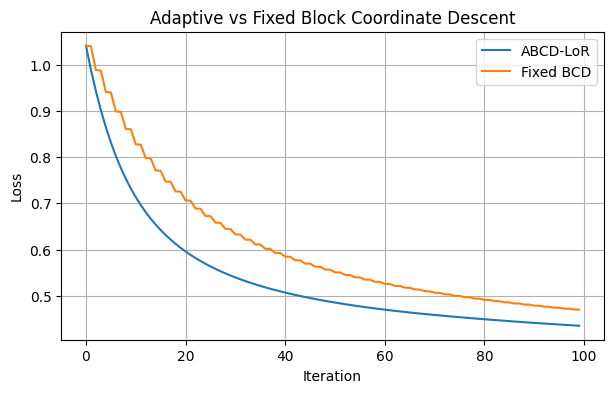

In [ ]:
plt.figure(figsize=(7,4))

plt.plot(
    history_abcd,
    label="ABCD-LoR"
)

plt.plot(
    history_fixed,
    label="Fixed BCD"
)

plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.title("Adaptive vs Fixed Block Coordinate Descent")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
# Example:
# D  = 150 cm
# VL = 0.5
# VR = 0.5

new_sensor = np.array([
    [150, 0.5, 0.5]
])

new_sensor_s = scaler.transform(
    new_sensor
)

new_sensor_b = np.c_[
    new_sensor_s,
    np.ones(1)
]

pred, prob = predict_abcd(
    new_sensor_b,
    W_abcd
)

actions = {
    0: "NO TURN",
    1: "LEFT TURN",
    2: "RIGHT TURN"
}

print(
    "Predicted action:",
    actions[int(pred[0])]
)

print(
    "Probabilities:",
    prob[0]
)


Predicted action: NO TURN
Probabilities: [0.59272419 0.21156628 0.19570954]


In [ ]:
def simulate_navigation(
    W,
    steps=200,
    speed=1.0
):
    x, y = 0.0, 0.0
    heading = 0.0

    path = [(x, y)]
    actions_taken = []

    for _ in range(steps):

        D_now = np.random.uniform(
            60, 200
        )

        VL_now = np.random.uniform(
            0.4, 1.0
        )

        VR_now = np.random.uniform(
            0.4, 1.0
        )

        z = np.array([[
            D_now,
            VL_now,
            VR_now
        ]])

        z_s = scaler.transform(z)

        z_b = np.c_[
            z_s,
            np.ones(1)
        ]

        action, _ = predict_abcd(
            z_b,
            W
        )

        action = int(action[0])

        if action == 1:
            heading += np.deg2rad(15)

        elif action == 2:
            heading -= np.deg2rad(15)

        x += speed * np.cos(heading)
        y += speed * np.sin(heading)

        path.append((x, y))
        actions_taken.append(action)

    return np.array(path), actions_taken

path, actions_taken = simulate_navigation(
    W_abcd
)


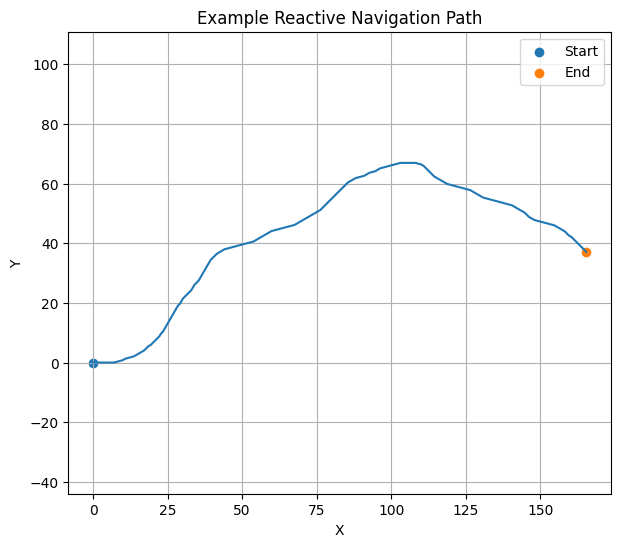

In [ ]:
plt.figure(figsize=(7,6))

plt.plot(
    path[:,0],
    path[:,1]
)

plt.scatter(
    path[0,0],
    path[0,1],
    label="Start"
)

plt.scatter(
    path[-1,0],
    path[-1,1],
    label="End"
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title(
    "Example Reactive Navigation Path"
)

plt.legend()
plt.axis("equal")
plt.grid(True)

plt.show()


In [ ]:
segment_lengths = np.sqrt(
    np.diff(path[:,0])**2 +
    np.diff(path[:,1])**2
)

path_length = np.sum(
    segment_lengths
)

turns = np.array(
    actions_taken
)

turn_only = turns[
    turns != 0
]

if len(turn_only) > 1:
    reversals = np.sum(
        turn_only[1:] != turn_only[:-1]
    )
else:
    reversals = 0

print(
    "Path length:",
    path_length
)

print(
    "Left/Right reversals:",
    reversals
)


Path length: 200.00000000000006
Left/Right reversals: 29


In [ ]:
print("ABCD-LoR implementation completed.")
print("Dataset samples:", len(data))
print("Train samples:", len(X_train))
print("Test samples:", len(X_test))
print("ABCD-LoR test accuracy:",
      accuracy_score(y_test, y_pred_abcd))
print("Mean 5-fold CV accuracy:",
      np.mean(cv_scores))



ABCD-LoR implementation completed.
Dataset samples: 292
Train samples: 233
Test samples: 59
ABCD-LoR test accuracy: 0.8305084745762712
Mean 5-fold CV accuracy: 0.8081823495032145
